
# Uczenie maszynowe — zajęcia 7
## Drzewa decyzyjne — od własnej implementacji do `DecisionTreeClassifier`

**Uniwersytet Warmińsko-Mazurski w Olsztynie**  
**Semestr 5, rok akademicki 2026/2027**  
**Prowadzący: mgr inż. Adrian Albrecht**

---

## Cel zajęć

Na tych zajęciach poznajemy **drzewa decyzyjne do klasyfikacji**.

Najpierw analizujemy mechanizm wyboru podziału, a następnie korzystamy z własnej implementacji drzewa. Na końcu porównujemy ją z gotowym:

```python
sklearn.tree.DecisionTreeClassifier
```

Po zajęciach osoba studiująca powinna umieć:

1. wyjaśnić strukturę drzewa decyzyjnego,
2. rozróżnić korzeń, węzeł wewnętrzny i liść,
3. wyjaśnić, czym jest zanieczyszczenie węzła,
4. obliczyć indeks Giniego,
5. wyjaśnić, jak wybierany jest próg podziału,
6. wyjaśnić ważoną jakość podziału,
7. opisać rekurencyjne budowanie drzewa,
8. wyjaśnić znaczenie `max_depth` i `min_samples_split`,
9. samodzielnie zaimplementować prosty klasyfikator drzewiasty,
10. użyć gotowego `DecisionTreeClassifier` i zinterpretować jego strukturę.

> **Ważne:** pełna implementacja `MyDecisionTreeClassifier` nie znajduje się w notebooku udostępnianym studentom.



## Plan zajęć — 90 minut

| Czas | Temat |
|---:|---|
| 0–10 min | Intuicja drzewa decyzyjnego |
| 10–25 min | Indeks Giniego |
| 25–40 min | Wybór najlepszego podziału |
| 40–50 min | Rekurencja i warunki stopu |
| 50–65 min | Demonstracja własnej implementacji |
| 65–75 min | Wpływ `max_depth` |
| 75–85 min | `DecisionTreeClassifier` z `scikit-learn` |
| 85–90 min | Zadanie własne i podsumowanie |



# 0. Przygotowanie środowiska


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)

np.set_printoptions(
    precision=4,
    suppress=True
)

RANDOM_STATE = 42



# 1. Intuicja drzewa decyzyjnego

Drzewo decyzyjne podejmuje decyzję poprzez serię prostych pytań.

Przykładowo:

```text
czy petal length <= 2.45?
        /             \
      TAK             NIE
      /                 \
  setosa        czy petal width <= 1.75?
                     /          \
                   TAK          NIE
                    /             \
              versicolor       virginica
```

Każdy **węzeł wewnętrzny** zawiera pytanie.

Każda **gałąź** odpowiada jednej z możliwych odpowiedzi.

Każdy **liść** zawiera końcową decyzję.



## 1.1. Podział dla cechy numerycznej

Dla cechy:

```text
petal length
```

możemy rozważyć pytanie:

$$
x_j \leq t
$$

gdzie:

- `j` — numer cechy,
- `t` — próg.

Dane dzielimy na dwie grupy:

$$
X_L
=
\{x : x_j \leq t\}
$$

oraz:

$$
X_R
=
\{x : x_j > t\}
$$

Pozostaje pytanie:

> **jak wybrać najlepszą cechę i najlepszy próg?**



# 2. Zanieczyszczenie węzła

Dobry węzeł powinien zawierać możliwie jednorodne klasy.

Jeżeli w węźle wszystkie obserwacje należą do jednej klasy, węzeł jest **czysty**.

Jeżeli klasy są mocno wymieszane, węzeł jest bardziej zanieczyszczony.

Jedną z popularnych miar jest **indeks Giniego**:

$$
Gini
=
1-
\sum_{k=1}^{K}
p_k^2
$$

gdzie:

- `K` — liczba klas,
- `p_k` — udział klasy `k` w węźle.



## 2.1. Przykład — węzeł całkowicie czysty

Załóżmy, że mamy:

```text
10 × klasa A
0  × klasa B
```

Wtedy:

$$
p_A=1
$$

$$
p_B=0
$$

więc:

$$
Gini
=
1-(1^2+0^2)
=
0
$$

Im bliżej zera, tym czystszy węzeł.



## 2.2. Przykład — dwie klasy po połowie

Jeżeli:

```text
5 × klasa A
5 × klasa B
```

to:

$$
p_A=0.5
$$

$$
p_B=0.5
$$

więc:

$$
Gini
=
1-
\left(
0.5^2+0.5^2
\right)
=
0.5
$$


In [2]:

def gini(y):
    _, counts = np.unique(
        y,
        return_counts=True
    )

    probabilities = (
        counts / len(y)
    )

    return (
        1
        - np.sum(
            probabilities ** 2
        )
    )


examples = {
    "10A, 0B": np.array(
        ["A"] * 10
    ),
    "8A, 2B": np.array(
        ["A"] * 8
        + ["B"] * 2
    ),
    "5A, 5B": np.array(
        ["A"] * 5
        + ["B"] * 5
    )
}

for name, values in examples.items():
    print(
        name,
        "-> Gini =",
        round(
            gini(values),
            4
        )
    )


10A, 0B -> Gini = 0.0
8A, 2B -> Gini = 0.32
5A, 5B -> Gini = 0.5



# 3. Jakość podziału

Po podziale mamy dwa węzły:

- lewy,
- prawy.

Nie wystarczy policzyć ich Giniego osobno.

Musimy uwzględnić również liczbę obserwacji w obu częściach.

Ważone zanieczyszczenie po podziale:

$$
G_{split}
=
\frac{n_L}{n}
G_L
+
\frac{n_R}{n}
G_R
$$

gdzie:

- `n_L` — liczba obserwacji po lewej,
- `n_R` — liczba obserwacji po prawej,
- `n` — liczba wszystkich obserwacji w bieżącym węźle.



## 3.1. Redukcja zanieczyszczenia

Jeżeli przed podziałem mieliśmy:

$$
G_{parent}
$$

a po podziale:

$$
G_{split}
$$

to poprawę możemy zapisać jako:

$$
\Delta G
=
G_{parent}
-
G_{split}
$$

Chcemy znaleźć taki podział, dla którego:

$$
\Delta G
$$

jest możliwie duże.



# 4. Prosty przykład podziału

Rozważmy jedną cechę:

```text
x = [1, 2, 3, 4, 5, 6]
```

i klasy:

```text
y = [A, A, A, B, B, B]
```

Naturalny próg znajduje się pomiędzy:

```text
3 i 4
```

czyli:

$$
t=3.5
$$


In [3]:

x = np.array([
    1, 2, 3, 4, 5, 6
])

y_demo = np.array([
    "A", "A", "A",
    "B", "B", "B"
])

threshold = 3.5

left = (
    y_demo[
        x <= threshold
    ]
)

right = (
    y_demo[
        x > threshold
    ]
)

parent_gini = gini(
    y_demo
)

left_gini = gini(
    left
)

right_gini = gini(
    right
)

weighted = (
    len(left) / len(y_demo)
    * left_gini
    + len(right) / len(y_demo)
    * right_gini
)

gain = (
    parent_gini
    - weighted
)

print(
    "Gini rodzica:",
    parent_gini
)

print(
    "Gini lewego:",
    left_gini
)

print(
    "Gini prawego:",
    right_gini
)

print(
    "Ważone Gini:",
    weighted
)

print(
    "Redukcja zanieczyszczenia:",
    gain
)


Gini rodzica: 0.5
Gini lewego: 0.0
Gini prawego: 0.0
Ważone Gini: 0.0
Redukcja zanieczyszczenia: 0.5



W tym przypadku podział jest idealny.

Po lewej została tylko klasa `A`.

Po prawej tylko klasa `B`.

Dlatego:

$$
G_{split}=0
$$



# 5. Skąd brać kandydatów na próg?

Nie musimy sprawdzać każdej możliwej liczby rzeczywistej.

Dla uporządkowanych unikalnych wartości:

$$
v_1<v_2<\dots<v_m
$$

możemy sprawdzać środki pomiędzy sąsiednimi wartościami:

$$
t_i
=
\frac{
v_i+v_{i+1}
}{2}
$$

Przykładowo dla:

```text
[1, 2, 3, 4]
```

otrzymujemy:

```text
1.5, 2.5, 3.5
```


In [4]:

values = np.array([
    1, 2, 3, 4
])

thresholds = (
    values[:-1]
    + values[1:]
) / 2

print(
    thresholds
)


[1.5 2.5 3.5]



# 6. Jak drzewo szuka najlepszego podziału?

Dla bieżącego węzła:

```text
dla każdej cechy:
    znajdź kandydatów na próg

    dla każdego progu:
        podziel dane na lewo i prawo
        policz Gini(lewo)
        policz Gini(prawo)
        policz ważone Gini
        policz redukcję zanieczyszczenia

wybierz podział dający największą redukcję
```

Następnie wykonujemy dokładnie ten sam proces dla obu dzieci.

To prowadzi do **rekurencyjnego** budowania drzewa.



# 7. Kiedy przestać dzielić?

Gdybyśmy zawsze dzielili dalej, drzewo mogłoby stać się bardzo głębokie.

Typowe warunki stopu to:

### 1. Węzeł jest czysty

$$
Gini=0
$$

### 2. Osiągnięto maksymalną głębokość

```python
max_depth
```

### 3. W węźle jest zbyt mało obserwacji

```python
min_samples_split
```

### 4. Nie istnieje podział poprawiający jakość węzła

Warunki stopu kontrolują złożoność drzewa.



# 8. Iris

Wykorzystamy zbiór Iris.

Najpierw dwie cechy, aby dało się narysować granice decyzyjne:

- `petal length`,
- `petal width`.


In [5]:

iris = load_iris()

X = iris.data[
    :,
    [2, 3]
]

y = iris.target

feature_names = [
    iris.feature_names[2],
    iris.feature_names[3]
]

print(
    X.shape
)

print(
    feature_names
)


(150, 2)
['petal length (cm)', 'petal width (cm)']


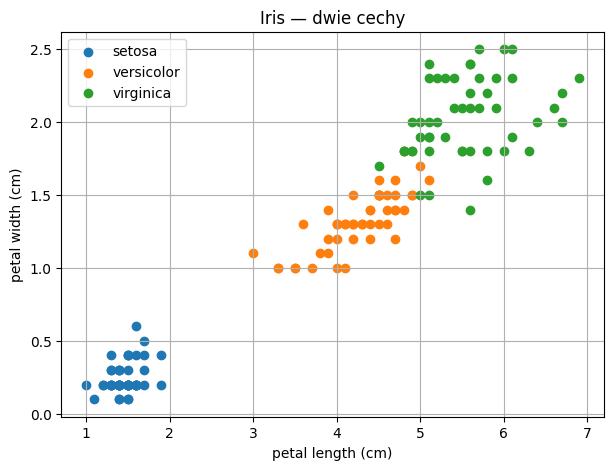

In [6]:

plt.figure(
    figsize=(7, 5)
)

for class_id, class_name in enumerate(
    iris.target_names
):
    mask = y == class_id

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        label=class_name
    )

plt.xlabel(
    feature_names[0]
)

plt.ylabel(
    feature_names[1]
)

plt.title(
    "Iris — dwie cechy"
)

plt.legend()
plt.grid()
plt.show()



# 9. Demonstracja własnej implementacji

Sprawdzamy, czy dostępny jest moduł:

```text
myDecisionTree.py
```

Pełna implementacja nie znajduje się w notebooku.


In [7]:

try:
    from myDecisionTree import MyDecisionTreeClassifier

    HAS_MY_TREE = True
    print("Znaleziono implementację.")

except ImportError:
    HAS_MY_TREE = False
    print("Nie znaleziono implementacji.")


Znaleziono implementację.


In [8]:

if HAS_MY_TREE:

    my_tree = MyDecisionTreeClassifier(
        max_depth=3,
        min_samples_split=2
    )

    my_tree.fit(
        X,
        y
    )

    print(
        my_tree.export_text(
            feature_names=feature_names
        )
    )


ROOT: petal length (cm) <= 2.4500 (n=150, gini=0.6667)
    TAK: LEAF -> 0 (n=50, gini=0.0000)
    NIE: petal width (cm) <= 1.7500 (n=100, gini=0.5000)
        TAK: petal length (cm) <= 4.9500 (n=54, gini=0.1680)
            TAK: LEAF -> 1 (n=48, gini=0.0408)
            NIE: LEAF -> 2 (n=6, gini=0.4444)
        NIE: petal length (cm) <= 4.8500 (n=46, gini=0.0425)
            TAK: LEAF -> 2 (n=3, gini=0.4444)
            NIE: LEAF -> 2 (n=43, gini=0.0000)



## 9.1. Jak czytać tekstowe drzewo?

Przykładowy fragment:

```text
ROOT: petal length <= ...
    TAK: ...
    NIE: ...
```

oznacza:

1. zacznij od korzenia,
2. sprawdź warunek,
3. przejdź odpowiednią gałęzią,
4. powtarzaj aż dojdziesz do liścia.

Predykcja drzewa to po prostu **przejście ścieżką od korzenia do liścia**.



# 10. Wizualizacja granic własnego drzewa


In [9]:

def plot_decision_regions(
    X,
    y,
    predict_function,
    title
):
    x_min = (
        X[:, 0].min() - 0.5
    )

    x_max = (
        X[:, 0].max() + 0.5
    )

    y_min = (
        X[:, 1].min() - 0.5
    )

    y_max = (
        X[:, 1].max() + 0.5
    )

    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            300
        ),
        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    grid = np.column_stack([
        xx.ravel(),
        yy.ravel()
    ])

    Z = predict_function(
        grid
    ).reshape(
        xx.shape
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.2
    )

    for class_id, class_name in enumerate(
        iris.target_names
    ):
        mask = y == class_id

        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            label=class_name
        )

    plt.xlabel(
        feature_names[0]
    )

    plt.ylabel(
        feature_names[1]
    )

    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


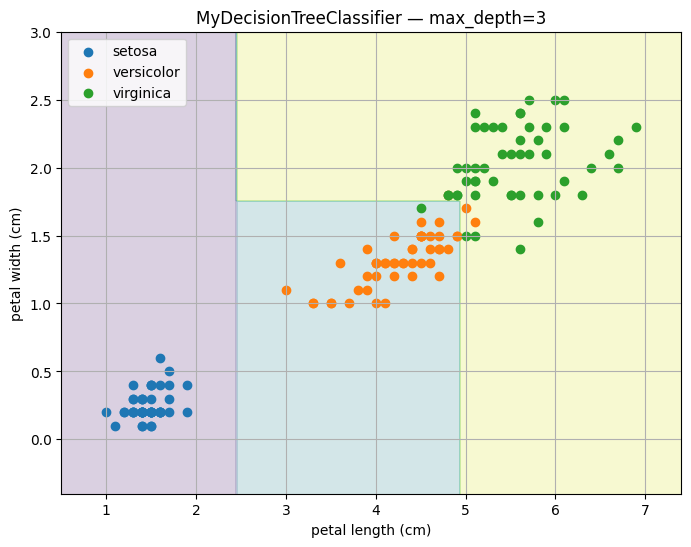

In [10]:

if HAS_MY_TREE:

    plot_decision_regions(
        X,
        y,
        my_tree.predict,
        "MyDecisionTreeClassifier — max_depth=3"
    )



# 11. Wpływ `max_depth`

Głębokość drzewa silnie wpływa na kształt granic decyzyjnych.

Płytkie drzewo:

- wykonuje mało podziałów,
- tworzy prostszą strukturę.

Głębokie drzewo:

- może tworzyć bardzo szczegółowe regiony,
- może reagować na pojedyncze obserwacje.

Nie będziemy tutaj oceniać modeli za pomocą metryk ani walidacji.

Interesuje nas **mechanizm i geometria podziałów**.


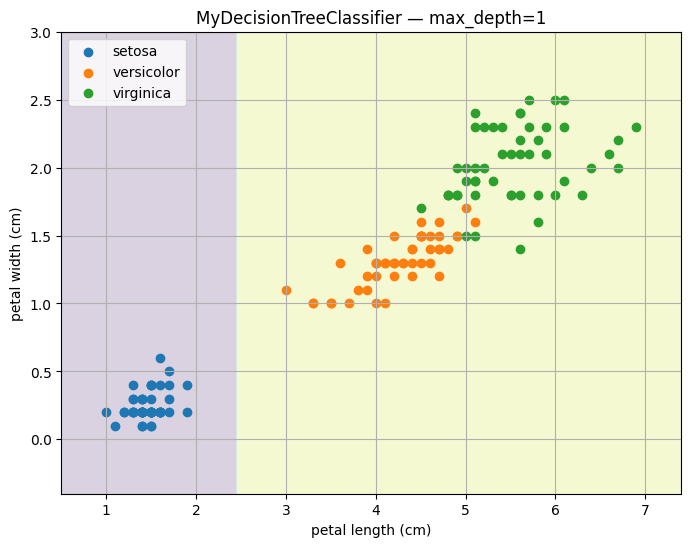

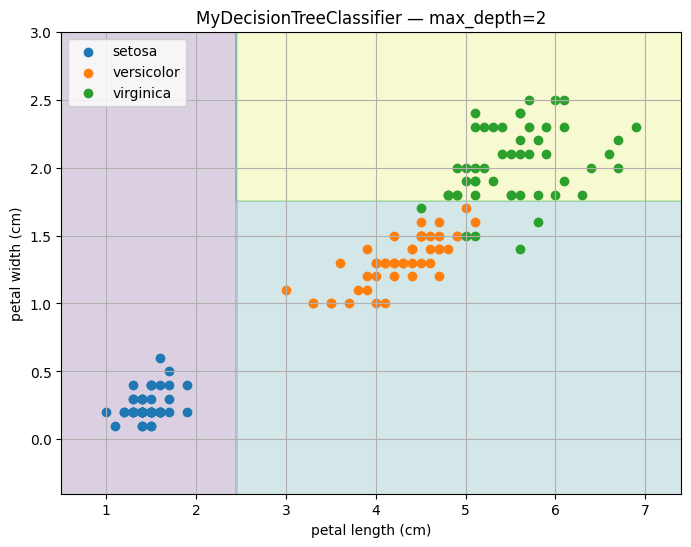

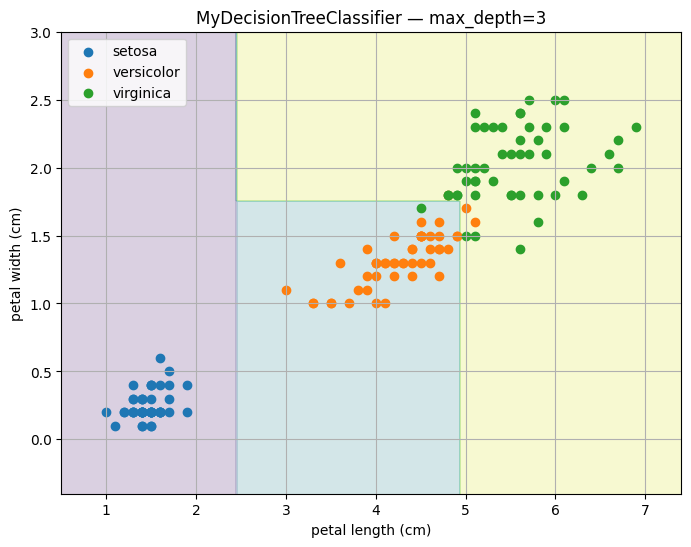

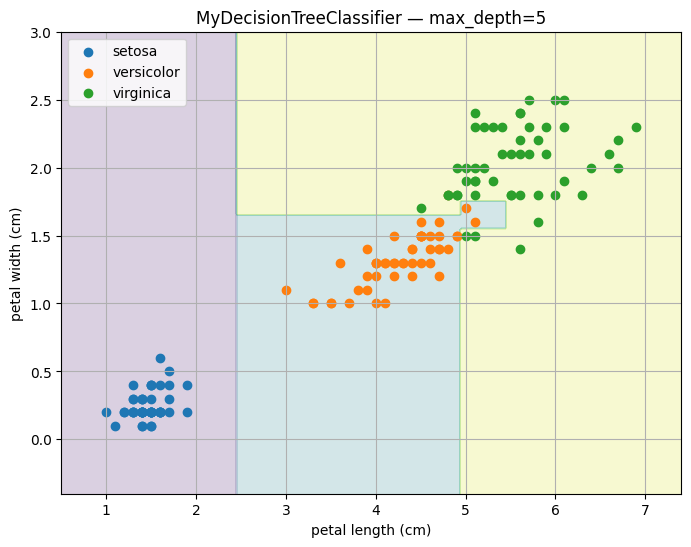

In [11]:

if HAS_MY_TREE:

    for depth in [
        1,
        2,
        3,
        5
    ]:
        model = MyDecisionTreeClassifier(
            max_depth=depth
        )

        model.fit(
            X,
            y
        )

        plot_decision_regions(
            X,
            y,
            model.predict,
            (
                "MyDecisionTreeClassifier "
                f"— max_depth={depth}"
            )
        )



# 12. Znaczenie cech

Jeżeli podział na danej cesze często i mocno zmniejsza zanieczyszczenie, cecha ma większy udział w budowie drzewa.

Własna implementacja udostępnia prostą wersję:

```python
feature_importances_
```

Jest ona wyznaczana na podstawie redukcji zanieczyszczenia uzyskanej dzięki kolejnym podziałom.


In [12]:

if HAS_MY_TREE:

    importance_df = pd.DataFrame({
        "cecha": feature_names,
        "znaczenie": (
            my_tree.feature_importances_
        )
    })

    display(
        importance_df
    )


,cecha,znaczenie
0,petal length (cm),0.585616
1,petal width (cm),0.414384



# 13. Gotowa implementacja — `DecisionTreeClassifier`

Teraz przechodzimy do gotowego drzewa z `scikit-learn`.

```python
from sklearn.tree import DecisionTreeClassifier
```

Ustawimy:

```python
criterion="gini"
```

aby użyć tego samego kryterium, które omawialiśmy wcześniej.


In [13]:

sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=RANDOM_STATE
)

sk_tree.fit(
    X,
    y
)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no


## 13.1. Tekstowa reprezentacja drzewa


In [14]:

print(
    export_text(
        sk_tree,
        feature_names=feature_names
    )
)


|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2




## 13.2. Graficzna reprezentacja drzewa


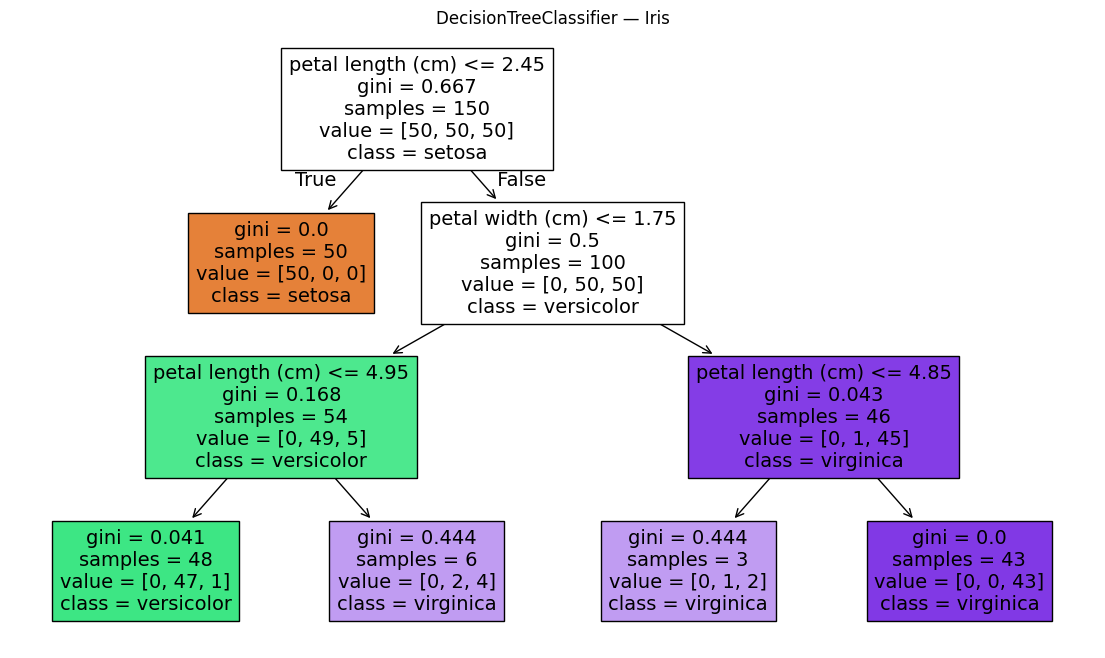

In [15]:

plt.figure(
    figsize=(14, 8)
)

plot_tree(
    sk_tree,
    feature_names=feature_names,
    class_names=iris.target_names,
    filled=True
)

plt.title(
    "DecisionTreeClassifier — Iris"
)

plt.show()



Na rysunku możemy odczytać między innymi:

- warunek podziału,
- wartość `gini`,
- liczbę obserwacji w węźle,
- rozkład klas,
- klasę przypisaną do węzła.



# 14. Granica decyzyjna gotowego drzewa


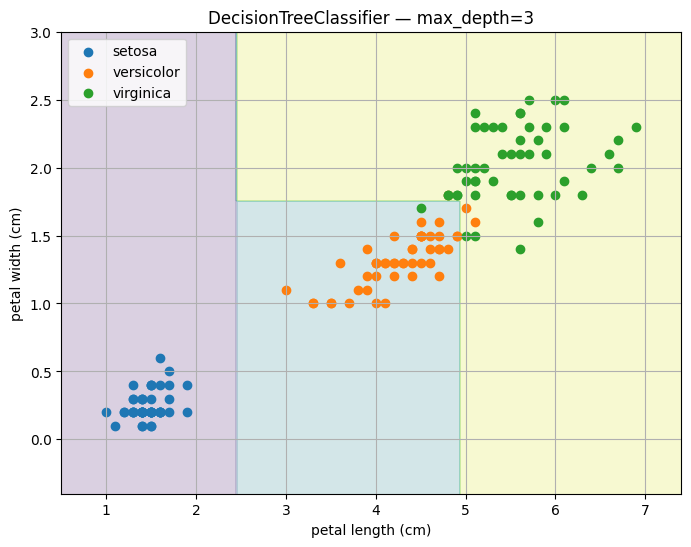

In [16]:

plot_decision_regions(
    X,
    y,
    sk_tree.predict,
    "DecisionTreeClassifier — max_depth=3"
)



# 15. Własna implementacja vs `scikit-learn`

Nie oczekujemy, że dwie implementacje zawsze zbudują identyczne drzewo.

Różnice mogą wynikać między innymi z:

- sposobu rozstrzygania remisów,
- szczegółów wyboru progów,
- dodatkowych warunków stopu,
- optymalizacji implementacyjnych.

Możemy jednak sprawdzić, czy dla tych samych obserwacji otrzymujemy podobne decyzje.


In [17]:

if HAS_MY_TREE:

    sample_indices = [
        0,
        50,
        100,
        70,
        120
    ]

    X_sample = X[
        sample_indices
    ]

    comparison = pd.DataFrame({
        "petal length": (
            X_sample[:, 0]
        ),
        "petal width": (
            X_sample[:, 1]
        ),
        "MyDecisionTree": (
            my_tree.predict(
                X_sample
            )
        ),
        "sklearn": (
            sk_tree.predict(
                X_sample
            )
        )
    })

    display(
        comparison
    )


,petal length,petal width,MyDecisionTree,sklearn
0,1.4,0.2,0,0
1,4.7,1.4,1,1
2,6.0,2.5,2,2
3,4.8,1.8,2,2
4,5.7,2.3,2,2



# 16. Gini a entropy

`DecisionTreeClassifier` pozwala również użyć entropii.

Dla rozkładu klas:

$$
p_1,p_2,\dots,p_K
$$

entropia ma postać:

$$
H
=
-
\sum_{k=1}^{K}
p_k
\log_2
p_k
$$

Podobnie jak Gini:

- jest mała dla czystych węzłów,
- rośnie, gdy klasy są bardziej wymieszane.

Na tych zajęciach własną implementację budujemy na **Gini**, ale warto wiedzieć, że istnieją inne kryteria.


In [18]:

tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=RANDOM_STATE
)

tree_entropy.fit(
    X,
    y
)

print(
    export_text(
        tree_entropy,
        feature_names=feature_names
    )
)


|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2




# 17. Pełne Iris — cztery cechy

Dotychczas używaliśmy dwóch cech tylko po to, aby móc narysować granice.

Drzewo może oczywiście pracować na wszystkich czterech cechach.


In [19]:

X_full = iris.data

full_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=RANDOM_STATE
)

full_tree.fit(
    X_full,
    y
)

print(
    export_text(
        full_tree,
        feature_names=iris.feature_names
    )
)


|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2




## 17.1. Znaczenie cech w gotowym drzewie


In [20]:

importance_df = pd.DataFrame({
    "cecha": iris.feature_names,
    "znaczenie": (
        full_tree.feature_importances_
    )
})

display(
    importance_df.sort_values(
        "znaczenie",
        ascending=False
    )
)


,cecha,znaczenie
2,petal length (cm),0.585616
3,petal width (cm),0.414384
0,sepal length (cm),0.000000
1,sepal width (cm),0.000000



# 18. Zadanie własne — `MyDecisionTreeClassifier`

Przygotuj własny plik:

```text
myDecisionTree.py
```

i zaimplementuj klasę:

```python
class MyDecisionTreeClassifier:
    ...
```

## Minimalne wymagania

Klasa powinna posiadać:

```python
fit(X, y)
predict(X)
```

oraz wewnętrzną reprezentację drzewa.

### Kryterium

Wykorzystaj indeks Giniego:

$$
Gini
=
1-
\sum_k
p_k^2
$$

### Wybór podziału

Dla każdej cechy:

1. uporządkuj unikalne wartości,
2. utwórz kandydatów na próg jako środki pomiędzy sąsiednimi wartościami,
3. podziel dane na lewo i prawo,
4. policz ważone zanieczyszczenie,
5. wybierz najlepszy podział.

### Rekurencja

Po znalezieniu podziału zbuduj osobno:

- lewe poddrzewo,
- prawe poddrzewo.

### Warunki stopu

Minimalnie obsłuż:

- czysty węzeł,
- `max_depth`,
- `min_samples_split`,
- brak podziału poprawiającego Gini.

### Liść

Liść powinien zwracać najczęściej występującą klasę w danym węźle.

### Dodatkowo

Warto zaimplementować tekstowe wyświetlanie drzewa, np.:

```python
export_text(...)
```

> Nie korzystamy wewnątrz własnej klasy z `DecisionTreeClassifier`.



# 19. Testy własnej implementacji

Po napisaniu drzewa sprawdź:

1. Czy potrafi utworzyć liść dla danych jednej klasy?
2. Czy dla prostego przykładu znajduje intuicyjny próg?
3. Czy `max_depth=1` tworzy wyłącznie jeden podział?
4. Czy `predict()` potrafi przejść od korzenia do liścia?
5. Co dzieje się po zwiększeniu `max_depth`?
6. Co zmienia `min_samples_split`?
7. Czy drzewo działa dla więcej niż dwóch klas?
8. Czy działa dla wszystkich czterech cech Iris?
9. Czy wynik własnego drzewa jest podobny do `DecisionTreeClassifier` dla prostych przykładów?



# 20. Pytania podsumowujące

1. Czym jest korzeń drzewa?
2. Czym jest liść?
3. Co oznacza zanieczyszczenie węzła?
4. Jak obliczamy indeks Giniego?
5. Kiedy Gini wynosi zero?
6. Dlaczego po podziale stosujemy średnią ważoną?
7. Co oznacza redukcja zanieczyszczenia?
8. Jak wybieramy kandydatów na próg dla cechy numerycznej?
9. Dlaczego drzewo buduje się rekurencyjnie?
10. Jakie warunki mogą zakończyć dalszy podział?
11. Co zmienia `max_depth`?
12. Co zmienia `min_samples_split`?
13. Jak wykonywana jest predykcja dla nowej obserwacji?
14. Dlaczego granice decyzyjne drzewa są zbudowane z podziałów równoległych do osi cech?
15. Czym różni się Gini od entropii?
16. Dlaczego dwie poprawne implementacje drzewa nie muszą mieć identycznej struktury?
17. Co oznacza `feature_importances_`?
18. Dlaczego gotowa biblioteka jest wygodniejsza w praktyce?
19. Co daje nam wcześniejsze napisanie własnej implementacji?



# 21. Najważniejsze wnioski

> **Drzewo decyzyjne buduje model poprzez serię prostych podziałów przestrzeni cech.**

> **Dobry podział zmniejsza zanieczyszczenie klas w powstałych węzłach.**

> **Indeks Giniego jest jednym z kryteriów pozwalających mierzyć czystość węzła.**

> **Budowa drzewa jest procesem rekurencyjnym i musi posiadać warunki stopu.**

> **Parametry takie jak `max_depth` kontrolują złożoność struktury drzewa.**

> **Po zrozumieniu własnej implementacji możemy bez problemu przejść do `DecisionTreeClassifier`, który realizuje ten sam ogólny mechanizm w znacznie bardziej dopracowanej postaci.**

Na kolejnych zajęciach przechodzimy do **baggingu i metod zespołowych**.
